# Verify AI-Extracted Values Against the PDF

Take the fields an LLM extracted from an invoice, find every value in the PDF, check that it is printed next to the right label, and mark each one as verified or wrong.

Companion notebook for the article [Verify AI-Extracted Values Against the PDF](https://pymupdf.io/blog/verify-ai-extracted-values-against-the-pdf) in the PyMuPDF grounding series. Tested with PyMuPDF 2.1.

In [1]:
%pip install -q pymupdf


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## Sample document
Creates the sample PDF used in the article. Replace the path with your own PDF to try it on real documents.

In [2]:
import pymupdf
doc = pymupdf.open(); p = doc.new_page()
B, R = "hebo", "helv"
p.insert_text((72, 80), "Northwind Cloud Services Ltd.", fontsize=16, fontname=B)
p.insert_text((72, 98), "12 Harbour Street, London EC2A 4BX, United Kingdom", fontsize=9, fontname=R)
p.insert_text((400, 80), "INVOICE", fontsize=20, fontname=B)
labels = [("Invoice number:", "INV-2026-0417"), ("Invoice date:", "October 15, 2026"),
          ("Due date:", "November 14, 2026"), ("PO number:", "PO-88213")]
y = 120
for l, v in labels:
    p.insert_text((360, y), l, fontsize=10, fontname=B); p.insert_text((450, y), v, fontsize=10, fontname=R); y += 16
p.insert_text((72, 140), "Bill to:", fontsize=10, fontname=B)
p.insert_text((72, 156), "Acme Corporation", fontsize=10, fontname=R)
p.insert_text((72, 170), "500 Market Street, San Francisco, CA 94105", fontsize=10, fontname=R)
rows = [["Description", "Qty", "Unit price", "Amount"],
        ["Cloud hosting, October 2026", "1", "8,400.00", "8,400.00"],
        ["Managed database service", "3", "1,250.00", "3,750.00"],
        ["Premium support plan", "1", "1,200.00", "1,200.00"]]
x = [72, 312, 362, 442, 522]; y0, h = 210, 20
for i, row in enumerate(rows):
    for j, cell in enumerate(row):
        r = pymupdf.Rect(x[j], y0 + i*h, x[j+1], y0 + (i+1)*h)
        p.draw_rect(r, color=(0.6, 0.6, 0.6), width=0.5)
        font = B if i == 0 else R
        w = pymupdf.get_text_length(cell, fontname=font, fontsize=9)
        xpos = r.x0 + 4 if j == 0 else r.x1 - 4 - w
        p.insert_text((xpos, r.y1 - 6), cell, fontsize=9, fontname=font)
tot = [("Subtotal", "13,350.00"), ("VAT (20%)", "2,670.00"), ("Total due (GBP)", "16,020.00")]
y = 310
for l, v in tot:
    font = B if l.startswith("Total") else R
    p.insert_text((362, y), l, fontsize=10, fontname=font)
    w = pymupdf.get_text_length(v, fontname=font, fontsize=10)
    p.insert_text((518 - w, y), v, fontsize=10, fontname=font); y += 18
p.insert_text((72, 400), "Payment terms: 30 days. Bank: Barclays, sort code 20-00-00, account 43210987.", fontsize=9, fontname=R)
doc.save("invoice.pdf")

## Grounding helpers
`locate()` comes from the first article in the series, [Cite Claude's Answers at the Exact Spot in the PDF](https://pymupdf.io/blog/cite-claude-answers-at-the-exact-spot-in-the-pdf). It is also part of [the PyMuPDF grounding skill](https://github.com/pymupdf/cookbook/tree/main/skills/grounding-skill).

In [3]:
import re
import pymupdf


def locate(page, cited_text):
    """Return the quads of cited_text on a page, or [] if not found."""
    text = " ".join(cited_text.split())          # collapse whitespace and line breaks
    quads = page.search_for(text, quads=True)    # case-insensitive, joins hyphenated words
    if quads:
        return quads
    return _locate_by_words(page, text)          # fallback for small differences


def _norm(word):
    return re.sub(r"[^\w%$.]", "", word).lower().rstrip(".")


def _locate_by_words(page, text):
    """Match the quote word by word, ignoring punctuation, case and hyphenation."""
    target = [_norm(w) for w in text.split() if _norm(w)]
    words = page.get_text("words", flags=pymupdf.TEXT_DEHYPHENATE)
    tokens = [(_norm(w[4]), pymupdf.Rect(w[:4])) for w in words]
    tokens = [t for t in tokens if t[0]]
    n = len(target)
    for i in range(len(tokens) - n + 1):
        if all(tokens[i + k][0] == target[k] for k in range(n)):
            return [r.quad for _, r in tokens[i:i + n]]
    return []

## Step 1: Extract the fields

Use any model and any extraction method. Ask for dates in ISO format and amounts as plain numbers, so they can be compared reliably:

```
Extract these fields from the invoice and answer with JSON only:
vendor, invoice_number, invoice_date, due_date, po_number,
subtotal, tax, total, bank_account, vat_number.
Write dates as YYYY-MM-DD and amounts as plain numbers. Use null for missing fields.
```

For the sample invoice, the model returned the following. Two values are wrong: the total has two digits swapped (the invoice says 16,020.00), and the VAT number does not appear on the invoice at all.

In [4]:
extracted = {                       # the model's answer
    "vendor": "Northwind Cloud Services Ltd.",
    "invoice_number": "INV-2026-0417",
    "invoice_date": "2026-10-15",
    "due_date": "2026-11-14",
    "po_number": "PO-88213",
    "subtotal": 13350.00,
    "tax": 2670.00,
    "total": 16200.00,
    "bank_account": "43210987",
    "vat_number": "GB 123 4567 89",
}

The same check works on JSON from any extractor, including PDF.co's AI Invoice Parser: map its field names to the labels printed on your invoices.

## Step 2: Find values by type

A value can be printed differently from how it was extracted. "16020.0" is printed as "16,020.00", and "2026-10-15" as "October 15, 2026". So each field is compared by its kind: text is located with the `locate()` function from the first article in this series, amounts are compared as numbers, and dates are compared as dates.

In [5]:
import re
from datetime import date, datetime

import pymupdf

DATE_PATTERNS = [
    (r"[A-Z][a-z]+ \d{1,2}, \d{4}", "%B %d, %Y"),     # October 15, 2026
    (r"\d{1,2} [A-Z][a-z]+ \d{4}", "%d %B %Y"),       # 15 October 2026
    (r"\d{4}-\d{2}-\d{2}", "%Y-%m-%d"),               # 2026-10-15
    (r"\d{1,2}/\d{1,2}/\d{4}", "%m/%d/%Y"),           # 10/15/2026 (US order)
    (r"\d{1,2}\.\d{1,2}\.\d{4}", "%d.%m.%Y"),         # 15.10.2026
]

def to_number(text):
    """'16,020.00' -> 16020.0, '(52)' -> -52.0, '$1,200' -> 1200.0; None if not a number."""
    t = re.sub(r"[,$€£\s]", "", str(text))
    if re.fullmatch(r"\(\d+(\.\d+)?\)", t):
        t = "-" + t[1:-1]
    try:
        return float(t)
    except ValueError:
        return None

def find_amount(page, value):
    """Rects of words on the page whose numeric value equals value."""
    target = to_number(value)
    return [pymupdf.Rect(w[:4]) for w in page.get_text("words")
            if (n := to_number(w[4])) is not None and abs(n - target) < 0.005]

def find_dates(page):
    """Every date printed on the page, as (date, rect)."""
    found = []
    for block in page.get_text("dict")["blocks"]:
        for line in block.get("lines", []):
            text = "".join(span["text"] for span in line["spans"])
            for pattern, fmt in DATE_PATTERNS:
                for m in re.finditer(pattern, text):
                    try:
                        d = datetime.strptime(m.group(), fmt).date()
                    except ValueError:
                        continue
                    for rect in page.search_for(m.group(), clip=line["bbox"]):
                        found.append((d, rect))
    return found

def find_value(page, value, kind):
    """Rects where value appears on the page, comparing by kind: text, amount or date."""
    if kind == "amount":
        return find_amount(page, value)
    if kind == "date":
        target = date.fromisoformat(value)
        return [rect for d, rect in find_dates(page) if d == target]
    quads = locate(page, str(value))
    return [q.rect for q in quads]

## Step 3: Check each value next to its label

Finding a value somewhere on the page is not enough. On the sample invoice, 1,200.00 appears twice in the line items: if the model had returned 1,200.00 as the tax, a plain search would confirm it. So when a field has a label, the value must be printed next to that label. If a different value is printed there, the field is a mismatch, and we report what the document actually says.

In [6]:
def same_line_right(rect, label):
    """True if rect is on the label's line, to its right."""
    middle = (rect.y0 + rect.y1) / 2
    return rect.x0 >= label.x1 - 1 and label.y0 <= middle <= label.y1

def printed_next_to(page, label_rect):
    """The text printed to the right of a label on the same line, with its rect."""
    words = [w for w in page.get_text("words") if same_line_right(pymupdf.Rect(w[:4]), label_rect)]
    if not words:
        return None, None
    rect = pymupdf.Rect()
    for w in words:
        rect |= pymupdf.Rect(w[:4])
    return " ".join(w[4] for w in words), rect

def verify_field(doc, name, value, kind="text", label=None):
    """Check one extracted value against the document.

    With a label, the value must be printed next to that label:
      'verified'  - the value is printed next to the label
      'mismatch'  - a different value is printed next to the label
    Without a label, the value only has to appear somewhere in the document.
    'not found' means neither the value nor the label was found.
    """
    elsewhere = None
    for page in doc:
        rects = find_value(page, value, kind)
        labels = page.search_for(label) if label else []
        if label and labels:
            near = [r for r in rects if same_line_right(r, labels[0])]
            if near:
                return {"field": name, "value": value, "status": "verified",
                        "page": page.number + 1, "rect": near[0]}
            printed, rect = printed_next_to(page, labels[0])
            return {"field": name, "value": value, "status": "mismatch",
                    "printed": printed, "page": page.number + 1, "rect": rect,
                    "found_elsewhere": bool(rects)}
        if rects and elsewhere is None:
            elsewhere = {"field": name, "value": value, "status": "verified",
                         "page": page.number + 1, "rect": rects[0]}
    if elsewhere:                                  # value found, but its label was not
        if label:
            elsewhere["note"] = "label not found"
        return elsewhere
    return {"field": name, "value": value, "status": "not found"}

The schema says what kind each field is and which label it sits next to. Fields without a fixed label, such as the vendor name, only have to appear somewhere in the document.

In [7]:
schema = {                          # field: (kind, label printed next to the value)
    "vendor": ("text", None),
    "invoice_number": ("text", "Invoice number:"),
    "invoice_date": ("date", "Invoice date:"),
    "due_date": ("date", "Due date:"),
    "po_number": ("text", "PO number:"),
    "subtotal": ("amount", "Subtotal"),
    "tax": ("amount", "VAT (20%)"),
    "total": ("amount", "Total due (GBP)"),
    "bank_account": ("text", None),
    "vat_number": ("text", "VAT number"),
}

doc = pymupdf.open("invoice.pdf")
results = [verify_field(doc, name, value, *schema[name]) for name, value in extracted.items()]
for r in results:
    extra = f'  printed: {r["printed"]}' if r["status"] == "mismatch" else ""
    where = f'page {r["page"]}' if "page" in r else ""
    print(f'{r["field"]:15} {str(r["value"]):30} {r["status"]:10} {where}{extra}')

vendor          Northwind Cloud Services Ltd.  verified   page 1
invoice_number  INV-2026-0417                  verified   page 1
invoice_date    2026-10-15                     verified   page 1
due_date        2026-11-14                     verified   page 1
po_number       PO-88213                       verified   page 1
subtotal        13350.0                        verified   page 1
tax             2670.0                         verified   page 1
total           16200.0                        mismatch   page 1  printed: 16,020.00
bank_account    43210987                       verified   page 1
vat_number      GB 123 4567 89                 not found  


Eight values are confirmed. The total is caught as a mismatch, with the correct figure from the invoice. The VAT number is reported as not found, because neither the value nor a "VAT number" label is on the invoice.

## Step 4: Mark the results on the invoice

A reviewer should see the result on the document itself. This marks each checked value with a green or red box and attaches a note with the extracted and printed values:

In [8]:
COLORS = {"verified": (0, 0.6, 0), "mismatch": (0.85, 0, 0)}

def mark_results(doc, results):
    """Box each checked value: green if verified, red if it does not match, with a note."""
    for r in results:
        if "rect" not in r:
            continue
        page = doc[r["page"] - 1]
        annot = page.add_rect_annot(r["rect"] + (-2, -2, 2, 2))
        annot.set_colors(stroke=COLORS[r["status"]])
        annot.set_border(width=1.2)
        note = f'{r["field"]}: extracted {r["value"]}'
        if r["status"] == "mismatch":
            note += f', document says {r["printed"]}'
        annot.set_info(content=note)
        annot.update()

mark_results(doc, results)
doc.save("invoice_checked.pdf")             # a new file; the original is unchanged

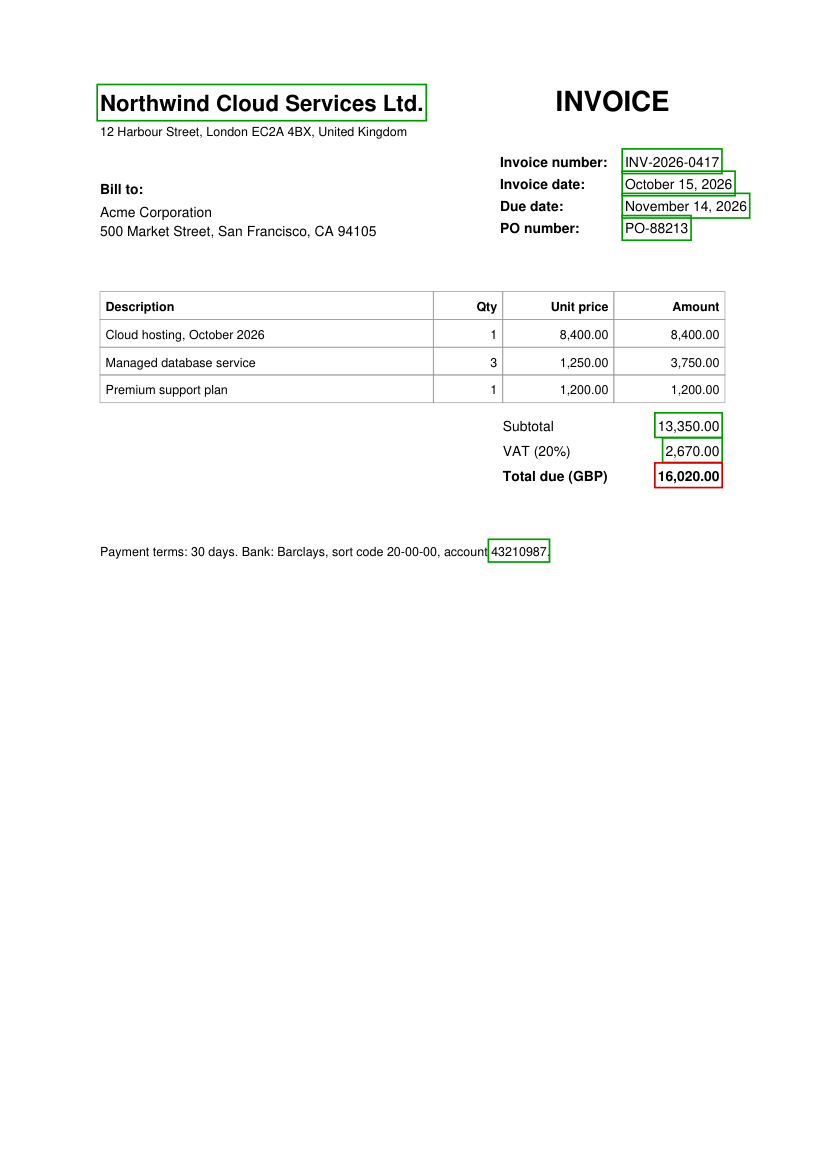

In [9]:
from IPython.display import Image, display
display(Image(pymupdf.open("invoice_checked.pdf")[0].get_pixmap(dpi=100).tobytes("png")))

## Going further
- **Check the arithmetic.** Once the values are verified against the document, check that they are consistent with each other:

In [10]:
values = {r["field"]: r["value"] for r in results if r["status"] == "verified"}
if {"subtotal", "tax", "total"} <= values.keys():
    if abs(values["subtotal"] + values["tax"] - values["total"]) > 0.005:
        print("Totals do not add up")

- **Line items.** For tables of line items, use the cell lookup from the table article in this series to check each row by its description and column.
- **Scanned invoices.** Combine this with the OCR article: report which verified values were read from a scan, so the reviewer can check them against the image.
- **An evidence pack.** Feed the results into the evidence pack from earlier in this series to produce one file per invoice for the audit trail.

## Limits to know
- The label check assumes the value is printed to the right of its label, on the same line. Layouts with values under their labels need a small extension of `same_line_right()`.
- `to_number()` reads US and UK number formats. European formats such as 1.234,56 need their own parser, and so do dates such as 03/04/2026, where the order of day and month depends on the country.
- Labels vary between vendors. Keep a small label list per vendor or document type, or let the LLM return the label it used for each field.
- A verified value is printed in the document; that does not make it correct. The check confirms that the extraction matches the invoice, not that the invoice is right.

## Next steps

- Read the full article: https://pymupdf.io/blog/verify-ai-extracted-values-against-the-pdf
- See everything on grounding with PyMuPDF: https://pymupdf.io/grounding